<a href="https://colab.research.google.com/github/AP24110010586-U/ML/blob/main/K_Means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means Clustering Algorithm


K-Means is an unsupervised machine learning algorithm used to group similar data points into a predefined number of clusters based on their similarities and distances. Each cluster has a centre called a centroid.

Working of K-Means
1. Choose the number of clusters (K).
2. Randomly select K centroids.
3. Assign each data point to its nearest centroid.
4. Recalculate the centroids.
5. Repeat until the centroids stop changing

Important Formulas in K-Means Clustering
1. Euclidean Distance
Used to calculate the distance between two data points.
\[
d(x,y)=\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
\]
2. Centroid Calculation
Used to find the centre of a cluster.
\[
C_j=\frac{1}{n}\sum_{i=1}^{n}X_i
\]
3. WCSS (Within-Cluster Sum of Squares)
Measures the sum of squared distances between data points and their centroids.
\[
WCSS=\sum_{j=1}^{K}\sum_{X_i\in C_j}(X_i-\mu_j)^2
\]

**Implementing K-Means Clustering in Python From Scratch**

In [5]:
#import libraries
import pandas as pd
import numpy as np
import random as rd
import matplotlib.pyplot as plt

# Helper step: Create synthetic datasets so that the code runs without FileNotFoundError
# 1. Create 'clustering.csv'
np.random.seed(42)
cluster_data = {
    'ApplicantIncome': np.random.randint(1000, 10000, 100),
    'LoanAmount': np.random.randint(10, 300, 100)
}
pd.DataFrame(cluster_data).to_csv('clustering.csv', index=False)

# 2. Create 'Wholesale customers data.csv'
wholesale_data = {
    'Channel': np.random.choice([1, 2], 100),
    'Region': np.random.choice([1, 2, 3], 100),
    'Fresh': np.random.randint(3, 112000, 100),
    'Milk': np.random.randint(55, 73000, 100),
    'Grocery': np.random.randint(3, 92000, 100),
    'Frozen': np.random.randint(25, 60000, 100),
    'Detergents_Paper': np.random.randint(3, 40000, 100),
    'Delicassen': np.random.randint(3, 47000, 100)
}
pd.DataFrame(wholesale_data).to_csv('Wholesale customers data.csv', index=False)
print("Datasets initialized successfully!")

Datasets initialized successfully!


In [9]:
data = pd.read_csv('clustering.csv')
data.head()

,ApplicantIncome,LoanAmount
0,8270,44
1,1860,236
2,6390,110
3,6191,140
4,6734,266


In [12]:
import os
from google.colab import files

# Check if datasets already exist before prompting for upload
if os.path.exists('clustering.csv') and os.path.exists('Wholesale customers data.csv'):
    print("Required datasets are already present in the workspace. Bypassing upload!")
else:
    print("Please upload your 'clustering.csv' or 'Wholesale customers data.csv' file if needed:")
    uploaded = files.upload()

Required datasets are already present in the workspace. Bypassing upload!


For this article, we will be taking only two variables from the data – “LoanAmount” and “ApplicantIncome.” This will make it easy to visualize the steps as well. Let’s pick these two variables and visualize the data points:

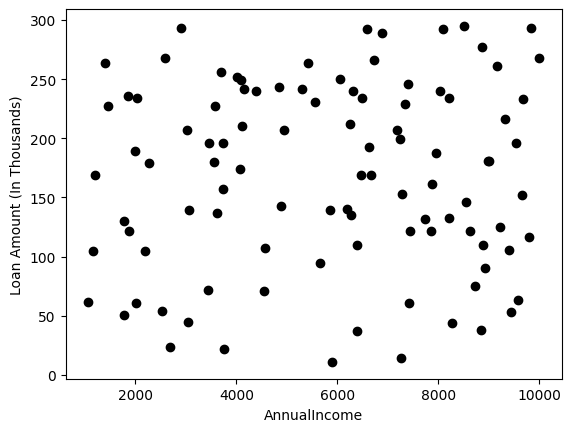

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv('clustering.csv')
data.head()


X = data[["LoanAmount","ApplicantIncome"]]
#Visualise data points
plt.scatter(X["ApplicantIncome"],X["LoanAmount"],c='black')
plt.xlabel('AnnualIncome')
plt.ylabel('Loan Amount (In Thousands)')
plt.show()

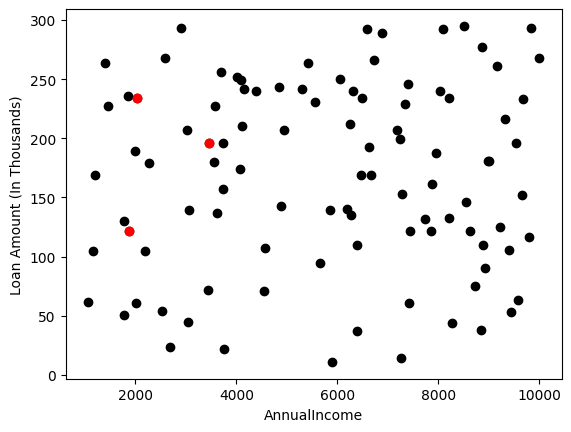

In [13]:
# Step 1 and 2 - Choose the number of clusters (k) and select random centroid for each cluster

#number of clusters
K=3

# Select random observation as centroids
Centroids = (X.sample(n=K))
plt.scatter(X["ApplicantIncome"],X["LoanAmount"],c='black')
plt.scatter(Centroids["ApplicantIncome"],Centroids["LoanAmount"],c='red')
plt.xlabel('AnnualIncome')
plt.ylabel('Loan Amount (In Thousands)')
plt.show()

In [14]:
# Step 3 - Assign all the points to the closest cluster centroid
# Step 4 - Recompute centroids of newly formed clusters
# Step 5 - Repeat step 3 and 4

diff = 1
j=0

while(diff!=0):
    XD=X
    i=1
    for index1,row_c in Centroids.iterrows():
        ED=[]
        for index2,row_d in XD.iterrows():
            d1=(row_c["ApplicantIncome"]-row_d["ApplicantIncome"])**2
            d2=(row_c["LoanAmount"]-row_d["LoanAmount"])**2
            d=np.sqrt(d1+d2)
            ED.append(d)
        X[i]=ED
        i=i+1

    C=[]
    for index,row in X.iterrows():
        min_dist=row[1]
        pos=1
        for i in range(K):
            if row[i+1] < min_dist:
                min_dist = row[i+1]
                pos=i+1
        C.append(pos)
    X["Cluster"]=C
    Centroids_new = X.groupby(["Cluster"]).mean()[["LoanAmount","ApplicantIncome"]]
    if j == 0:
        diff=1
        j=j+1
    else:
        diff = (Centroids_new['LoanAmount'] - Centroids['LoanAmount']).sum() + (Centroids_new['ApplicantIncome'] - Centroids['ApplicantIncome']).sum()
        print(diff.sum())
    Centroids = X.groupby(["Cluster"]).mean()[["LoanAmount","ApplicantIncome"]]

/tmp/ipykernel_862/3142618123.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[i]=ED
/tmp/ipykernel_862/3142618123.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[i]=ED
/tmp/ipykernel_862/3142618123.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[i

1783.3940595716197
1039.1099822112758
594.7917928927051
297.9358459832745
401.66362535149096
96.53020780961984
188.41188475390172
269.8037240192526
280.36193133379834
278.5050929462676
475.64281943546735


/tmp/ipykernel_862/3142618123.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[i]=ED
/tmp/ipykernel_862/3142618123.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Cluster"]=C
/tmp/ipykernel_862/3142618123.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-cop

482.6124446552814
100.21505376344075
304.09042097125644
103.81435274964687
84.96821112610593
83.63172947383498
162.95353925353865
183.2191876750704
161.78676470588172
81.39723851417446
0.0


/tmp/ipykernel_862/3142618123.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Cluster"]=C


When this difference is 0, we stop the training. Let’s now visualize the clusters we have got:

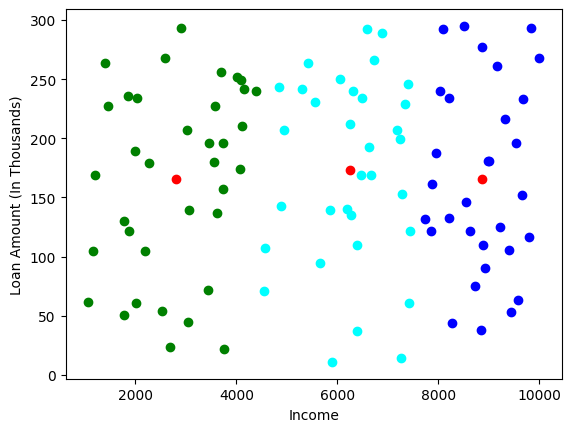

In [15]:
color=['blue','green','cyan']
for k in range(K):
    data=X[X["Cluster"]==k+1]
    plt.scatter(data["ApplicantIncome"],data["LoanAmount"],c=color[k])
plt.scatter(Centroids["ApplicantIncome"],Centroids["LoanAmount"],c='red')
plt.xlabel('Income')
plt.ylabel('Loan Amount (In Thousands)')
plt.show()

**Implementing K-Means Clustering in Python**

In [16]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.cluster import KMeans

print("KMeans library imported successfully!")

KMeans library imported successfully!


In [17]:
# reading the data and looking at the first five rows of the data
data=pd.read_csv("Wholesale customers data.csv")
data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1,1,50303,68440,74463,27380,8430,40943
1,2,1,22680,40213,89933,37757,24288,40444
2,1,3,55612,65472,6804,4860,37629,23336
3,2,3,96828,23344,72270,20184,22931,39653
4,1,2,56664,9878,48139,38835,19201,34677


In [18]:
# statistics of the data
data.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,100.00,100.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000
mean,1.55,2.010000,59721.880000,37270.440000,45587.390000,31654.940000,19096.53000,22191.670000
std,0.50,0.810225,31510.910095,21850.080396,26462.572569,18157.977821,11460.16072,14361.694249
min,1.00,1.000000,1153.000000,467.000000,1327.000000,34.000000,58.00000,12.000000
25%,1.00,1.000000,31828.750000,18738.750000,23962.750000,16626.500000,9803.00000,10245.000000
50%,2.00,2.000000,60899.000000,37445.000000,41890.000000,33502.500000,18153.50000,20376.000000
75%,2.00,3.000000,86792.500000,59119.000000,67950.250000,47386.250000,26424.25000,35485.000000
max,2.00,3.000000,111724.000000,72991.000000,91795.000000,59877.000000,39814.00000,46688.000000


In [19]:
# standardizing the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# statistics of scaled data
pd.DataFrame(data_scaled).describe()

,0,1,2,3,4,5,6,7
count,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02
mean,-1.021405e-16,2.375877e-16,8.215650e-17,-1.067202e-16,5.551115e-18,8.382184e-17,1.154632e-16,1.196265e-16
std,1.005038e+00,1.005038e+00,1.005038e+00,1.005038e+00,1.005038e+00,1.005038e+00,1.005038e+00,1.005038e+00
min,-1.105542e+00,-1.252847e+00,-1.868049e+00,-1.692847e+00,-1.680992e+00,-1.750208e+00,-1.669649e+00,-1.552143e+00
25%,-1.105542e+00,-1.252847e+00,-8.896490e-01,-8.524019e-01,-8.212951e-01,-8.318190e-01,-8.150278e-01,-8.360333e-01
50%,9.045340e-01,-1.240443e-02,3.754414e-02,8.029234e-03,-1.404254e-01,1.022618e-01,-8.270223e-02,-1.270614e-01
75%,9.045340e-01,1.228038e+00,8.634151e-01,1.004968e+00,8.493324e-01,8.707226e-01,6.426294e-01,9.302732e-01
max,9.045340e-01,1.228038e+00,1.658603e+00,1.643038e+00,1.754946e+00,1.562081e+00,1.816889e+00,1.714264e+00


Create a kmeans function and fit it on the data:

In [20]:
# defining the kmeans function with initialization as k-means++
kmeans = KMeans(n_clusters=2, init='k-means++')

# fitting the k means algorithm on scaled data
kmeans.fit(data_scaled)

KMeans(n_clusters=2)

In [21]:

# inertia on the fitted data
kmeans.inertia_

700.2665580294253

Text(0, 0.5, 'Inertia')

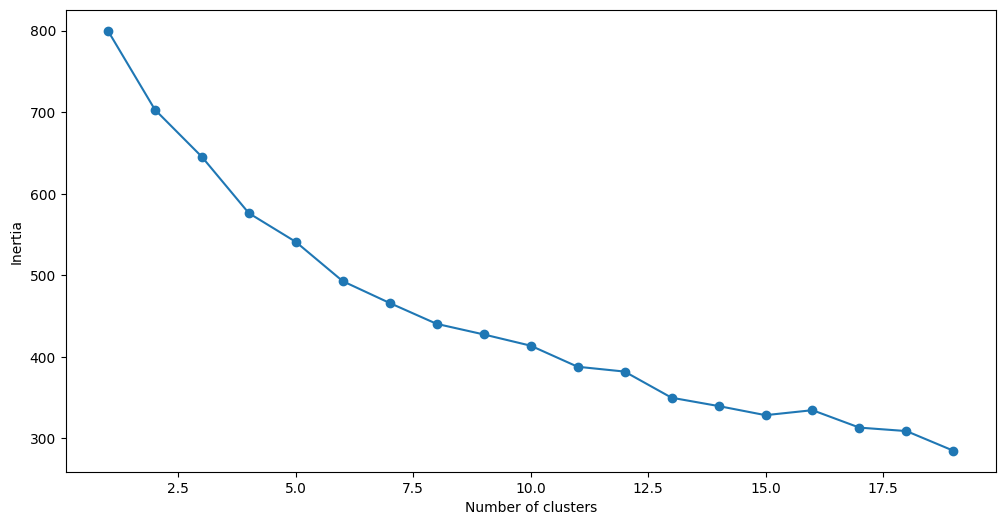

In [22]:
# fitting multiple k-means algorithms and storing the values in an empty list
SSE = []
for cluster in range(1,20):
    # Removed deprecated n_jobs argument to prevent TypeError in newer scikit-learn versions
    kmeans = KMeans(n_clusters=cluster, init='k-means++')
    kmeans.fit(data_scaled)
    SSE.append(kmeans.inertia_)

# converting the results into a dataframe and plotting them
frame = pd.DataFrame({'Cluster':range(1,20), 'SSE':SSE})
plt.figure(figsize=(12,6))
plt.plot(frame['Cluster'], frame['SSE'], marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')

In [23]:
# k means using 5 clusters and k-means++ initialization
# Removed deprecated n_jobs argument
kmeans = KMeans(n_clusters=5, init='k-means++')
kmeans.fit(data_scaled)
pred = kmeans.predict(data_scaled)

In [24]:
frame = pd.DataFrame(data_scaled)
frame['cluster'] = pred
frame['cluster'].value_counts()

,count
cluster,
2,24
1,23
0,21
3,19
4,13


**Conclusion**

K-Means is an unsupervised learning algorithm used to group similar data points into clusters. It works by assigning points to the nearest centroid and updating the clusters repeatedly. The Elbow Method helps in finding the optimal number of clusters, while K-Means++ improves the selection of initial centroids.